# ESS 118 final project Python code: 
# By Sina Shamsian and Lily Lai group #2  

In [20]:
print("Sina Shamsian, group #2 ")

Sina Shamsian, group #2 


## Group context for final project

In [21]:
# what is our groups main research question? 
research_question = """The research question for our project is: How has the snow depth across the CONUS changed over the past 40 years, 
and what are the dominant modes of spatiotemporal variability in that change?"""
print(research_question)

The research question for our project is: How has the snow depth across the CONUS changed over the past 40 years, 
and what are the dominant modes of spatiotemporal variability in that change?


In [ ]:
# What are the datasets that we are using ?
datasets= """We are using the following datasets for our project:we will analyze a gridded snow depth dataset. 
This dataset integrates satellite observations, ground-based measurements, and model outputs to produce a 
comprehensive record of snow conditions, making it well-suited for investigating long-term trends and 
variability in snow depth across the region. Some other datasets that we used was the elevation dataset and the era 2m temperature dataset, and the era 5 solar raditation dataset.
"""
print(datasets)

We are using the following datasets for our project:we will analyze a gridded snow depth dataset. 
This dataset integrates satellite observations, ground-based measurements, and model outputs to produce a 
comprehensive record of snow conditions, making it well-suited for investigating long-term trends and 
variability in snow depth across the region. Some other datasets that we used was the elevation dataset and the era 2m temperature dataset, and the era 5 solar raditation dataset.



## Importing Python packages 

In [29]:
import numpy as np                            # numerical operations
import pandas as pd                           # tabular data
import matplotlib.pyplot as plt               # plotting
from sklearn.preprocessing import StandardScaler   # standardize variables
from sklearn.decomposition import PCA              # dimensionality reduction
import xarray as xr                                     # multi-dimensional arrays
import geopandas as gpd                                 # shapefiles and vector data
from shapely.geometry import shape                      # geometry conversion
from cartopy.feature import NaturalEarthFeature         # coastlines and borders
from statsmodels.tsa.seasonal import seasonal_decompose   # seasonal decomposition of time series
import os                    # file and folder navigation
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import root_mean_squared_error
import shap
import rasterio                            # read raster/GeoTIFF files
import numpy as np                         # numerical operations
from rasterio.transform import array_bounds  # compute spatial extent from transform
from rasterio.mask import mask as rio_mask   # clip raster to polygon
from sklearn.cluster import KMeans
from scipy.stats import pearsonr     
import matplotlib.dates as mdates                           

## Loading in Snow depth dataset and other useful datasets

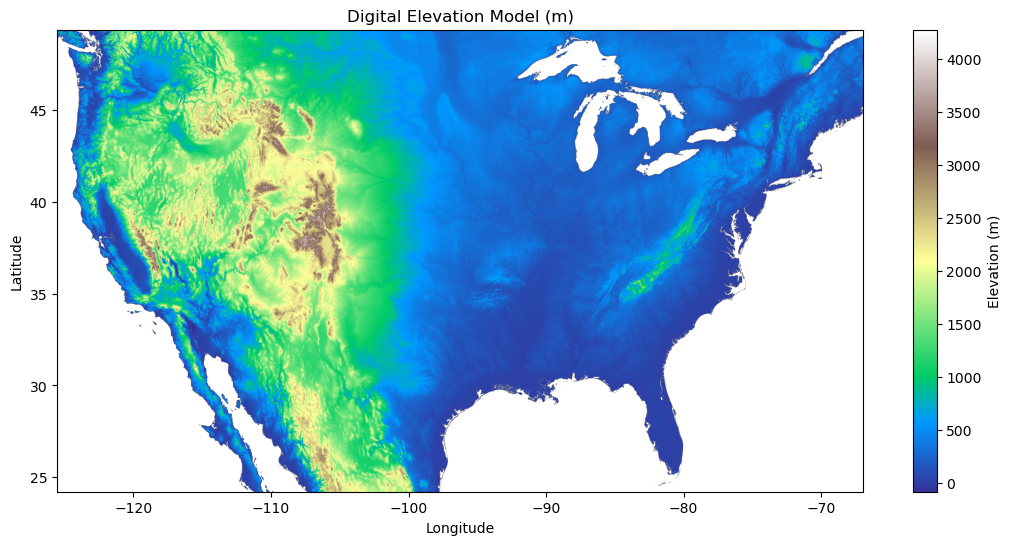

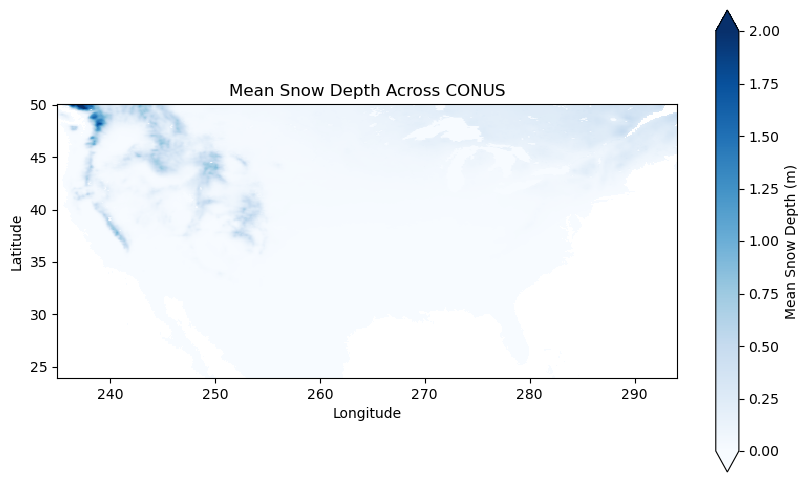

In [ ]:
data_folder = '/Users/sina/Desktop/ESS_118/datasets/'     # folder where all datasets are stored
os.listdir(data_folder)

ds_snowdepth = xr.open_dataset(data_folder + 'snowdepth_conus.nc')
ds_snowdepth
sde = ds_snowdepth['sde']
sde.shape

elev_file = data_folder + '/elevation_1km.tif'

ds_t2m = xr.open_dataset(data_folder + '/ERA5_Land_temp_precip_1950_2026.nc')
ds_ssrd = xr.open_dataset(data_folder + '/era5_ssrd_1950_2025.nc')

#conus bounds
conus_lon_min, conus_lon_max = 235, 294  # equivalent to -125 to -66
conus_lat_min, conus_lat_max = 25, 50

#clipping to conus
ds_t2m_us = ds_t2m.sel(
    longitude=slice(conus_lon_min, conus_lon_max),
    latitude=slice(conus_lat_max, conus_lat_min))  # latitude descending in ERA5

ds_ssrd_us = ds_ssrd.sel(
    longitude=slice(conus_lon_min, conus_lon_max),
    latitude=slice(conus_lat_max, conus_lat_min))  # latitude descending in ERA5)

#extract data arrays
t2m  = ds_t2m_us['t2m']    # 2 m air temperature  (time, lat, lon)
ssrd = ds_ssrd_us['ssrd']  # surface solar radiation  (time, lat, lon)

with rasterio.open(elev_file) as src:
    elev          = src.read(1).astype(float)  # read elevation values
    elev_transform = src.transform              # spatial transform
    elev_crs       = src.crs                   # coordinate reference system
    nodata         = src.nodata                # fill value for missing data

# Some dataset come with pre-defined no data areas, use the next code for this dataset

elev[elev == nodata] = np.nan              # replace fill values with NaN
elev[elev == 0] = np.nan                 # replace zero values with NaN (if needed)

bounds = array_bounds(elev.shape[0], elev.shape[1], elev_transform)  # raster bounding box
extent = [bounds[0], bounds[2], bounds[1], bounds[3]]                 # [left, right, bottom, top]
plt.figure(figsize=(13, 6))
plt.imshow(elev, extent=extent, cmap='terrain', aspect='auto')        # plot with geographic coordinates
plt.colorbar(label='Elevation (m)')
plt.title('Digital Elevation Model (m)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()

# Load coastline and country boundaries for map overlays
coastline  = NaturalEarthFeature('physical', 'coastline', '50m')
coastline_gdf  = gpd.GeoDataFrame(geometry=[shape(g) for g in coastline.geometries()])

sde_mean = sde.mean(dim='valid_time',skipna=True)
fig, ax = plt.subplots(figsize=(10, 6))
sde_mean.plot(ax=ax, cmap='Blues', cbar_kwargs={'label': 'Mean Snow Depth (m)'}, vmin=0, vmax=2)
coastline_gdf.plot(ax=ax, color='black', linewidth=0.5)
ax.set_title('Mean Snow Depth Across CONUS')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
plt.show()  


# Category #1 Seasonal decomposition of Snow depth dataset

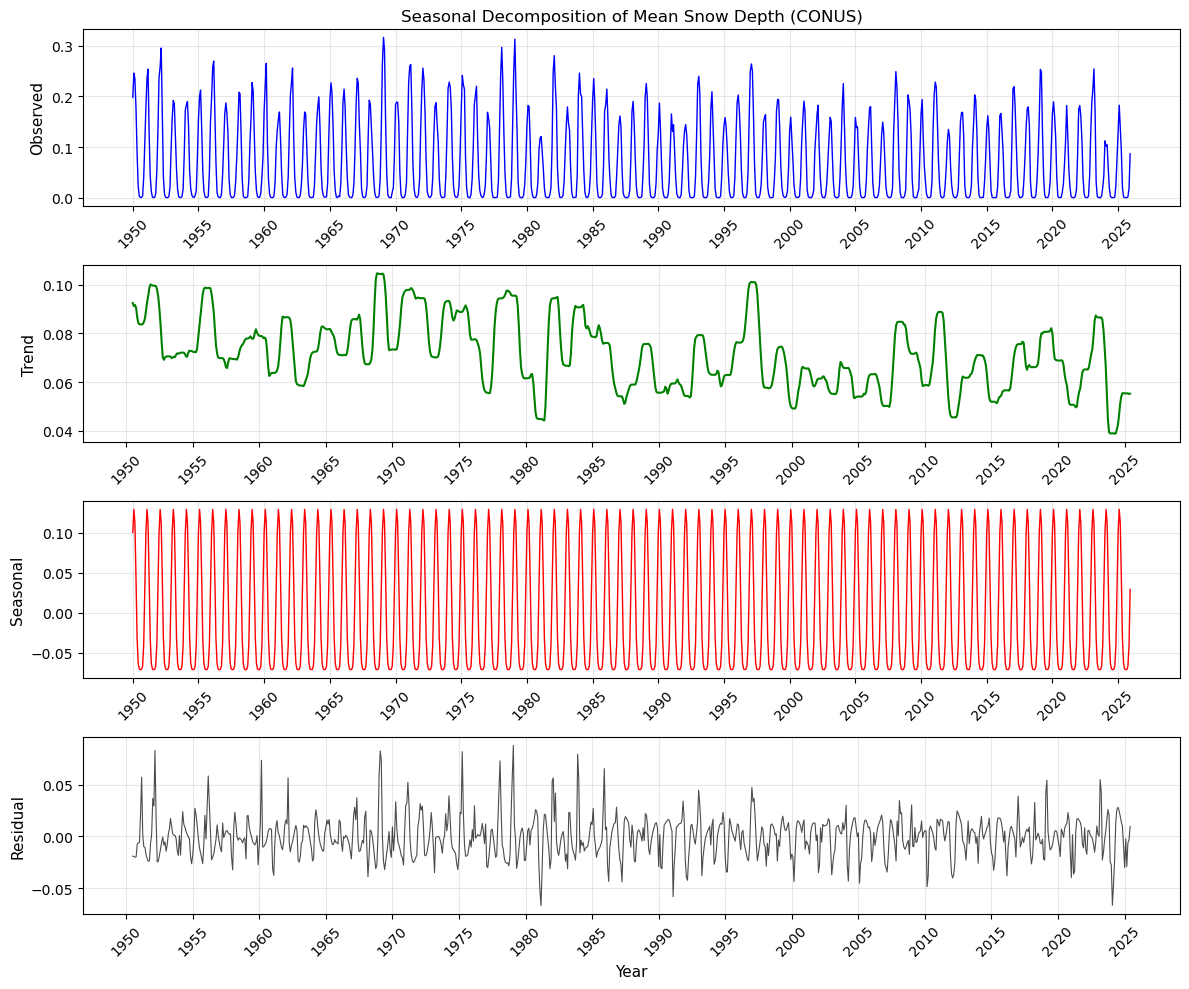

Seasonal Decomposition Results:
  Trend variance: 0.000202
  Seasonal variance: 0.005724
  Residual variance: 0.000382

Monthly mean shape: (912, 261, 591)
Climatology shape: (12, 261, 591)


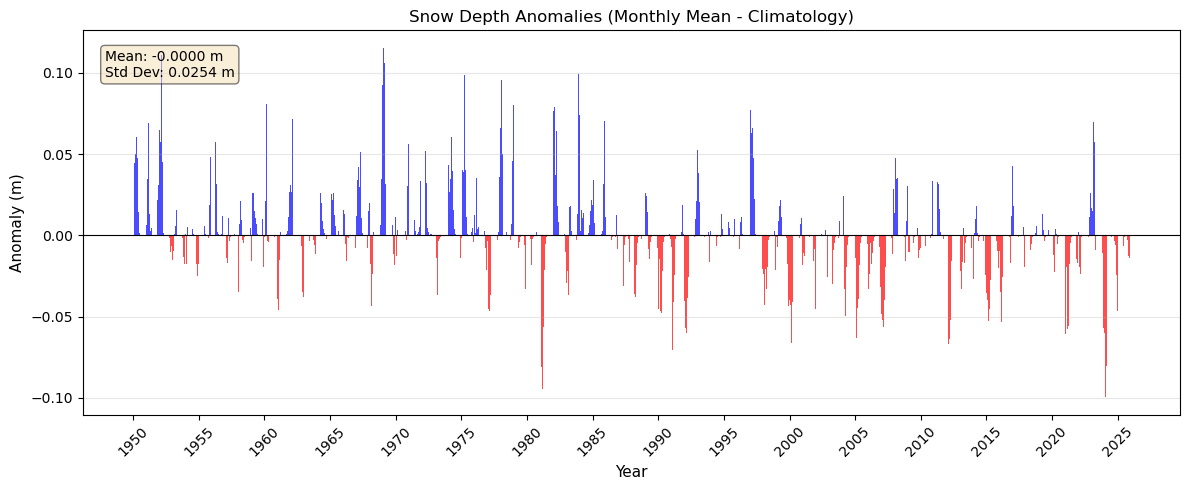


Anomaly Analysis Results:
  Mean anomaly: -0.000000 m
  Std dev of anomalies: 0.025370 m
  Max anomaly: 0.115358 m
  Min anomaly: -0.099555 m


In [ ]:
# # METHOD 1: SEASONAL DECOMPOSITION
# # Compute spatial mean time series
# sde_full = sde.values
# sde_mean_ts = np.nanmean(sde_full, axis=(1, 2))  # mean across lat/lon for each time step

# # Apply seasonal decomposition
# # Assuming roughly monthly data, use a period of 12 for annual seasonality
# decomposition = seasonal_decompose(sde_mean_ts, model='additive', period=12)

# # Plot seasonal decomposition
# fig, axes = plt.subplots(4, 1, figsize=(12, 10))

# # Original time series
# axes[0].plot(decomposition.observed, 'b-', linewidth=1)
# axes[0].set_ylabel('Observed', fontsize=11)
# axes[0].set_title('Seasonal Decomposition of Mean Snow Depth (CONUS)', fontsize=12)
# axes[0].grid(True, alpha=0.3)

# # Trend
# axes[1].plot(decomposition.trend, 'g-', linewidth=1.5)
# axes[1].set_ylabel('Trend', fontsize=11)
# axes[1].grid(True, alpha=0.3)

# # Seasonal
# axes[2].plot(decomposition.seasonal, 'r-', linewidth=1)
# axes[2].set_ylabel('Seasonal', fontsize=11)
# axes[2].grid(True, alpha=0.3)

# # Residual
# axes[3].plot(decomposition.resid, 'k-', linewidth=0.8, alpha=0.7)
# axes[3].set_ylabel('Residual', fontsize=11)
# axes[3].set_xlabel('Time Index', fontsize=11)
# axes[3].grid(True, alpha=0.3)

# plt.tight_layout()
# plt.show()

# print("Seasonal Decomposition Results:")
# print(f"  Trend variance: {np.nanvar(decomposition.trend):.6f}")
# print(f"  Seasonal variance: {np.nanvar(decomposition.seasonal):.6f}")
# print(f"  Residual variance: {np.nanvar(decomposition.resid):.6f}")

# # METHOD 2: ANOMALY ANALYSIS
# # Compute monthly mean
# sde_monthly = sde.resample(valid_time='1MS').mean()  # monthly mean
# print(f"\nMonthly mean shape: {sde_monthly.shape}")

# # Compute climatological mean for each calendar month
# sde_clim = sde_monthly.groupby('valid_time.month').mean('valid_time')
# print(f"Climatology shape: {sde_clim.shape}")

# # Compute anomalies: monthly mean - climatology
# sde_anom = sde_monthly.groupby('valid_time.month') - sde_clim

# # Compute spatial mean anomalies
# anom_mean_ts = sde_anom.mean(dim=['longitude', 'latitude']).values

# # Plot anomalies
# fig, ax = plt.subplots(figsize=(12, 5))
# ax.bar(range(len(anom_mean_ts)), anom_mean_ts, color=['red' if x < 0 else 'blue' for x in anom_mean_ts], alpha=0.7)
# ax.axhline(y=0, color='black', linestyle='-', linewidth=0.8)
# ax.set_xlabel('Month Index', fontsize=11)
# ax.set_ylabel('Anomaly (m)', fontsize=11)
# ax.set_title('Snow Depth Anomalies (Monthly Mean - Climatology)', fontsize=12)
# ax.grid(True, alpha=0.3, axis='y')

# # Add statistics
# mean_anom = np.nanmean(anom_mean_ts)
# std_anom = np.nanstd(anom_mean_ts)
# ax.text(0.02, 0.95, f'Mean: {mean_anom:.4f} m\nStd Dev: {std_anom:.4f} m', 
#         transform=ax.transAxes, verticalalignment='top',
#         bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5), fontsize=10)

# plt.tight_layout()
# plt.show()

# print("\nAnomaly Analysis Results:")
# print(f"  Mean anomaly: {mean_anom:.6f} m")
# print(f"  Std dev of anomalies: {std_anom:.6f} m")
# print(f"  Max anomaly: {np.nanmax(anom_mean_ts):.6f} m")
# print(f"  Min anomaly: {np.nanmin(anom_mean_ts):.6f} m")

# METHOD 1: SEASONAL DECOMPOSITION
# Compute spatial mean time series
sde_full = sde.values
sde_mean_ts = np.nanmean(sde_full, axis=(1, 2))  # mean across lat/lon for each time step

# Extract time values
time_vals = sde['valid_time'].values

# Apply seasonal decomposition
# Assuming roughly monthly data, use a period of 12 for annual seasonality
decomposition = seasonal_decompose(sde_mean_ts, model='additive', period=12)

# Plot seasonal decomposition
fig, axes = plt.subplots(4, 1, figsize=(12, 10))

# Original time series
axes[0].plot(time_vals, decomposition.observed, 'b-', linewidth=1)
axes[0].set_ylabel('Observed', fontsize=11)
axes[0].set_title('Seasonal Decomposition of Mean Snow Depth (CONUS)', fontsize=12)
axes[0].grid(True, alpha=0.3)

# Trend
axes[1].plot(time_vals, decomposition.trend, 'g-', linewidth=1.5)
axes[1].set_ylabel('Trend', fontsize=11)
axes[1].grid(True, alpha=0.3)

# Seasonal
axes[2].plot(time_vals, decomposition.seasonal, 'r-', linewidth=1)
axes[2].set_ylabel('Seasonal', fontsize=11)
axes[2].grid(True, alpha=0.3)

# Residual
axes[3].plot(time_vals, decomposition.resid, 'k-', linewidth=0.8, alpha=0.7)
axes[3].set_ylabel('Residual', fontsize=11)
axes[3].set_xlabel('Year', fontsize=11)
axes[3].grid(True, alpha=0.3)

# Format x-axis ticks as years on all axes
for ax in axes:
    ax.xaxis.set_major_locator(mdates.YearLocator(5))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    plt.setp(ax.xaxis.get_majorticklabels(), rotation=45)

plt.tight_layout()
plt.show()

print("Seasonal Decomposition Results:")
print(f"  Trend variance: {np.nanvar(decomposition.trend):.6f}")
print(f"  Seasonal variance: {np.nanvar(decomposition.seasonal):.6f}")
print(f"  Residual variance: {np.nanvar(decomposition.resid):.6f}")

# METHOD 2: ANOMALY ANALYSIS
# Compute monthly mean
sde_monthly = sde.resample(valid_time='1MS').mean()  # monthly mean
print(f"\nMonthly mean shape: {sde_monthly.shape}")

# Compute climatological mean for each calendar month
sde_clim = sde_monthly.groupby('valid_time.month').mean('valid_time')
print(f"Climatology shape: {sde_clim.shape}")

# Compute anomalies: monthly mean - climatology
sde_anom = sde_monthly.groupby('valid_time.month') - sde_clim

# Compute spatial mean anomalies
anom_mean_ts = sde_anom.mean(dim=['longitude', 'latitude']).values

# Extract monthly time coordinate as pandas datetime
time_monthly = pd.to_datetime(sde_monthly['valid_time'].values)

# Plot anomalies
fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(time_monthly, anom_mean_ts,
       color=['red' if x < 0 else 'blue' for x in anom_mean_ts],
       alpha=0.7,
       width=20)
ax.axhline(y=0, color='black', linestyle='-', linewidth=0.8)
ax.xaxis.set_major_locator(mdates.YearLocator(5))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.setp(ax.xaxis.get_majorticklabels(), rotation=45)
ax.autoscale(axis='y')
ax.set_xlabel('Year', fontsize=11)
ax.set_ylabel('Anomaly (m)', fontsize=11)
ax.set_title('Snow Depth Anomalies (Monthly Mean - Climatology)', fontsize=12)
ax.grid(True, alpha=0.3, axis='y')

# Add statistics
mean_anom = np.nanmean(anom_mean_ts)
std_anom = np.nanstd(anom_mean_ts)
ax.text(0.02, 0.95, f'Mean: {mean_anom:.4f} m\nStd Dev: {std_anom:.4f} m',
        transform=ax.transAxes, verticalalignment='top',
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5), fontsize=10)

plt.tight_layout()
plt.show()

print("\nAnomaly Analysis Results:")
print(f"  Mean anomaly: {mean_anom:.6f} m")
print(f"  Std dev of anomalies: {std_anom:.6f} m")
print(f"  Max anomaly: {np.nanmax(anom_mean_ts):.6f} m")
print(f"  Min anomaly: {np.nanmin(anom_mean_ts):.6f} m")

### Explanation of results 

In [ ]:
written_description = """Each analysis reveals that the snow depth across the CONUS has been decreasing overtime resulting in a negative trend. The seasonal decompostion shows a clear seasonal cycle with peaks in the winter months and troughs in the summer, which is expected for snow depths. The overall trend from the seasonal decomposition shows that snow depth has been decreasing overtime."""
print(written_description)

Each analysis reveals that the snow depth across the CONUS has been decreasing overtime resulting in a negative trend. The seasonal decompostion shows a clear seasonal cycle with peaks in the winter months and troughs in the summer, which is expected for snow depths. The overall trend from the seasonal decomposition shows that snow depth has been decreasing overtime.


# Category #1 Spatial correlation map using decomposition 

Computing correlations with shapes: sde_anom=(912, 261, 591), t2m_anom=(912, 261, 591)
Grid: 261 lats × 591 lons = 154251 pixels
Time steps: 912 months

Performing pixel-wise seasonal decomposition...
  → Snow Depth
      lat 1/261
      lat 6/261
      lat 11/261
      lat 16/261
      lat 21/261
      lat 26/261
      lat 31/261
      lat 36/261
      lat 41/261
      lat 46/261
      lat 51/261
      lat 56/261
      lat 61/261
      lat 66/261
      lat 71/261
      lat 76/261
      lat 81/261
      lat 86/261
      lat 91/261
      lat 96/261
      lat 101/261
      lat 106/261
      lat 111/261
      lat 116/261
      lat 121/261
      lat 126/261
      lat 131/261
      lat 136/261
      lat 141/261
      lat 146/261
      lat 151/261
      lat 156/261
      lat 161/261
      lat 166/261
      lat 171/261
      lat 176/261
      lat 181/261
      lat 186/261
      lat 191/261
      lat 196/261
      lat 201/261
      lat 206/261
      lat 211/261
      lat 216/261
      lat 221/

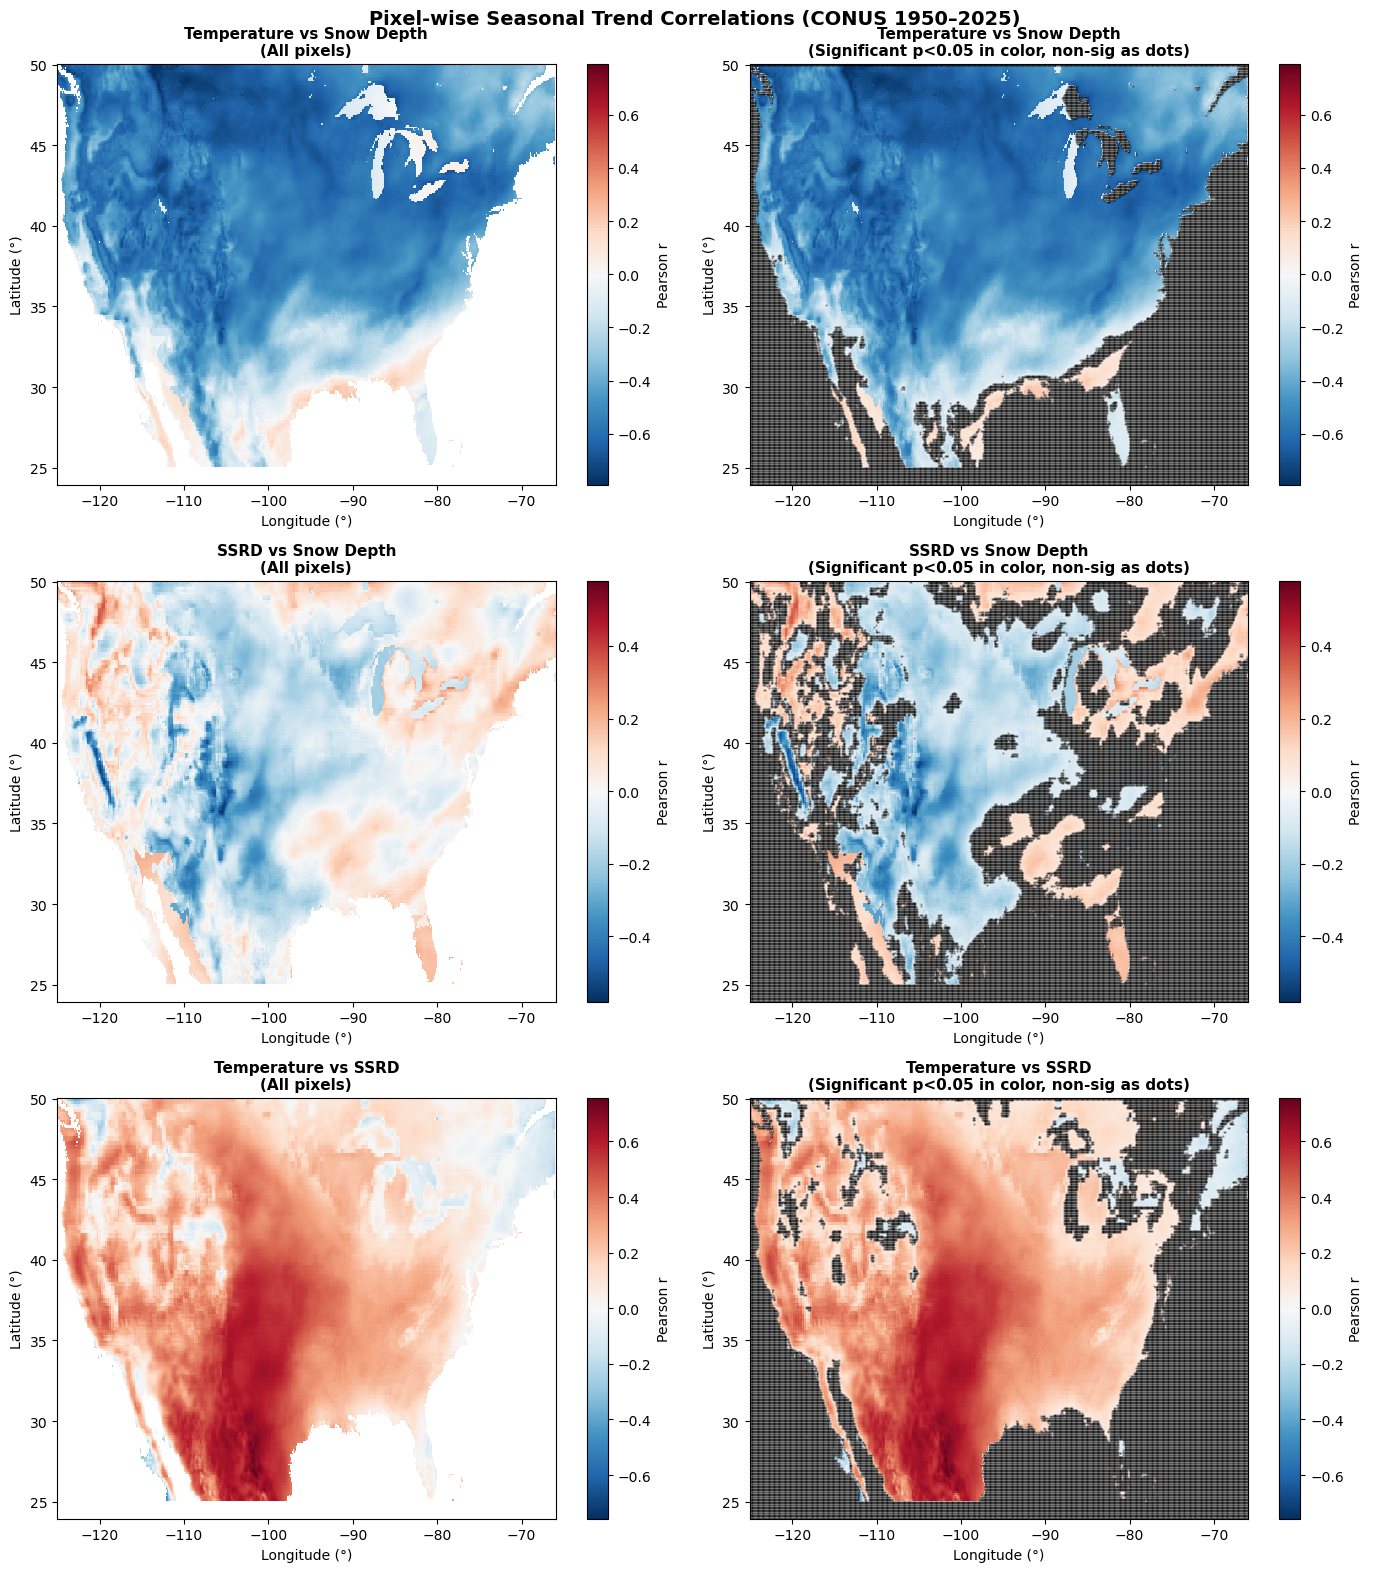


PIXEL-WISE TREND CORRELATION SUMMARY

Temperature vs Snow Depth:
  Mean r:              -0.4438
  Std dev:             0.2094
  Range:               [-0.7915, 0.2841]
  Valid pixels:        105645
  Significant (p<0.05):99797 / 105645

SSRD vs Snow Depth:
  Mean r:              -0.0516
  Std dev:             0.1327
  Range:               [-0.5798, 0.3708]
  Valid pixels:        106280
  Significant (p<0.05):67621 / 106280

Temperature vs SSRD:
  Mean r:              0.2557
  Std dev:             0.1916
  Range:               [-0.4868, 0.7573]
  Valid pixels:        105645
  Significant (p<0.05):91869 / 105645


In [ ]:

# Pixel-wise Seasonal Decomposition

# Step 1: Prepare temperature and snow depth data on the same grid
t2m_aligned = t2m.interp(
    longitude=sde.longitude,
    latitude=sde.latitude,
    method='nearest'
)

# Step 2: Extract seasonal anomalies for both variables
sde_monthly = sde.resample(valid_time='1MS').mean()
t2m_monthly = t2m_aligned.resample(valid_time='1MS').mean()

# Align both datasets to the same time dimension
sde_monthly, t2m_monthly = xr.align(sde_monthly, t2m_monthly, join='inner')

# Compute climatology for each month
sde_clim = sde_monthly.groupby('valid_time.month').mean('valid_time')
t2m_clim = t2m_monthly.groupby('valid_time.month').mean('valid_time')

# Compute anomalies
sde_anom_monthly = sde_monthly.groupby('valid_time.month') - sde_clim
t2m_anom_monthly = t2m_monthly.groupby('valid_time.month') - t2m_clim

# Sort by time
sde_anom_monthly = sde_anom_monthly.sortby('valid_time')
t2m_anom_monthly = t2m_anom_monthly.sortby('valid_time')

# Convert to numpy
sde_anom_data = sde_anom_monthly.values  # shape: (time, lat, lon)
t2m_anom_data = t2m_anom_monthly.values  # shape: (time, lat, lon)

# Resample and align ssrd to match sde monthly grid
ssrd_monthly = ssrd.resample(valid_time='1MS').mean()
ssrd_monthly = ssrd_monthly.interp(
    longitude=sde_monthly.longitude,
    latitude=sde_monthly.latitude,
    method='nearest'
)

# Align to common times with sde and t2m
_, ssrd_monthly = xr.align(sde_monthly, ssrd_monthly, join='inner')

# Climatology and anomaly
ssrd_clim        = ssrd_monthly.groupby('valid_time.month').mean('valid_time')
ssrd_anom_monthly = ssrd_monthly.groupby('valid_time.month') - ssrd_clim
ssrd_anom_monthly = ssrd_anom_monthly.sortby('valid_time')

# Step 3: Compute pixel-by-pixel spatial correlations
n_time, n_lat, n_lon = sde_anom_data.shape
correlation_map = np.full((n_lat, n_lon), np.nan)
pval_map = np.full((n_lat, n_lon), np.nan)

print(f"Computing correlations with shapes: sde_anom={sde_anom_data.shape}, t2m_anom={t2m_anom_data.shape}")

lats = sde.latitude.values
lons = sde.longitude.values
n_time_monthly = len(sde_anom_monthly['valid_time'])

print(f"Grid: {len(lats)} lats × {len(lons)} lons = {len(lats)*len(lons)} pixels")
print(f"Time steps: {n_time_monthly} months")

# Initialize 3D trend storage (lat, lon, time)
sde_trend_map  = np.full((len(lats), len(lons), n_time_monthly), np.nan)
t2m_trend_map  = np.full((len(lats), len(lons), n_time_monthly), np.nan)
ssrd_trend_map = np.full((len(lats), len(lons), n_time_monthly), np.nan)

# Extract monthly anomaly arrays (time, lat, lon)
sde_monthly_vals  = sde_anom_monthly.values
t2m_monthly_vals  = t2m_anom_monthly.values
ssrd_monthly_vals = ssrd_anom_monthly.values

# Variable registry for decomposition loop
decomp_targets = [
    ('Snow Depth',   sde_monthly_vals,  sde_trend_map),
    ('Temperature',  t2m_monthly_vals,  t2m_trend_map),
    ('SSRD',         ssrd_monthly_vals, ssrd_trend_map),
]

print("\nPerforming pixel-wise seasonal decomposition...")
for name, vals, trend_map in decomp_targets:
    print(f"  → {name}")
    for i in range(len(lats)):
        if i % 5 == 0:
            print(f"      lat {i+1}/{len(lats)}")
        for j in range(len(lons)):
            series = vals[:, i, j]
            if not np.all(np.isnan(series)) and np.sum(~np.isnan(series)) > 24:
                try:
                    decomp = seasonal_decompose(pd.Series(series).dropna(),
                                                model='additive', period=12,
                                                extrapolate_trend='freq')
                    trend = decomp.trend.values
                    trend_map[i, j, :len(trend)] = trend
                except:
                    pass

print("Decomposition complete!")

# Pixel-wise Correlation on Trend Components
pairs = [
    ('Temperature', 'Snow Depth',  t2m_trend_map,  sde_trend_map),
    ('SSRD',        'Snow Depth',  ssrd_trend_map, sde_trend_map),
    ('Temperature', 'SSRD',        t2m_trend_map,  ssrd_trend_map),
]

r_maps = {}
p_maps = {}

print("\nComputing pixel-wise correlations between trend components...")
for label_a, label_b, map_a, map_b in pairs:
    key   = f"{label_a} vs {label_b}"
    r_map = np.full((len(lats), len(lons)), np.nan)
    p_map = np.full((len(lats), len(lons)), np.nan)

    for i in range(len(lats)):
        for j in range(len(lons)):
            a_trend = map_a[i, j, :]
            b_trend = map_b[i, j, :]
            valid   = ~np.isnan(a_trend) & ~np.isnan(b_trend)
            if valid.sum() > 10:
                try:
                    r_map[i, j], p_map[i, j] = pearsonr(a_trend[valid], b_trend[valid])
                except:
                    pass

    r_maps[key] = r_map
    p_maps[key] = p_map
    print(f"  ✓ {key}")

print("Correlations computed!")


# Wrap as xarray DataArrays

lons_display = np.where(lons > 180, lons - 360, lons)
lon_grid, lat_grid = np.meshgrid(lons_display, lats)

r_das = {key: xr.DataArray(r_maps[key],
             coords={'latitude': lats, 'longitude': lons_display},
             dims=['latitude', 'longitude'])
         for key in r_maps}


# Plot: 3 rows × 2 columns
# Left  = full correlation map
# Right = significant (color) vs. non-significant (dots)


fig, axes = plt.subplots(3, 2, figsize=(14, 16))

for row, (label_a, label_b, _, __) in enumerate(pairs):
    key    = f"{label_a} vs {label_b}"
    r_da   = r_das[key]
    p_map  = p_maps[key]

    # Non-significant pixel coordinates (p >= 0.05 or NaN)
    nonsig_mask = (p_map >= 0.05) | np.isnan(p_map)
    nonsig_lons = lon_grid[nonsig_mask]
    nonsig_lats = lat_grid[nonsig_mask]

    vmax = np.nanmax(np.abs(r_maps[key]))
    plot_kwargs = dict(x='longitude', y='latitude',
                       cmap='RdBu_r', vmin=-vmax, vmax=vmax,
                       cbar_kwargs={'label': 'Pearson r'})

    # Left panel — full correlation map
    r_da.plot(ax=axes[row, 0], **plot_kwargs)
    axes[row, 0].set_title(f'{key}\n(All pixels)', fontsize=11, fontweight='bold')
    axes[row, 0].set_xlabel('Longitude (°)')
    axes[row, 0].set_ylabel('Latitude (°)')

    # Right panel — significance overlay
    r_da.plot(ax=axes[row, 1], **plot_kwargs)
    axes[row, 1].scatter(nonsig_lons, nonsig_lats,
                         color='black', s=0.5, alpha=0.3, zorder=3)
    axes[row, 1].set_title(f'{key}\n(Significant p<0.05 in color, non-sig as dots)',
                            fontsize=11, fontweight='bold')
    axes[row, 1].set_xlabel('Longitude (°)')
    axes[row, 1].set_ylabel('Latitude (°)')

plt.suptitle('Pixel-wise Seasonal Trend Correlations (CONUS 1950–2025)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Summary Statistics

print("\n" + "="*70)
print("PIXEL-WISE TREND CORRELATION SUMMARY")
print("="*70)

for label_a, label_b, _, __ in pairs:
    key   = f"{label_a} vs {label_b}"
    r_map = r_maps[key]
    p_map = p_maps[key]
    valid = ~np.isnan(r_map)

    print(f"\n{key}:")
    print(f"  Mean r:              {np.nanmean(r_map):.4f}")
    print(f"  Std dev:             {np.nanstd(r_map):.4f}")
    print(f"  Range:               [{np.nanmin(r_map):.4f}, {np.nanmax(r_map):.4f}]")
    print(f"  Valid pixels:        {valid.sum()}")
    print(f"  Significant (p<0.05):{np.sum(p_map < 0.05)} / {np.sum(~np.isnan(p_map))}")

print("="*70)

In [ ]:
written_description = """"""
print(written_description)


## Category #2: PCA of Snowdepth and K-means clustering


Reshaping for PCA:
  Original: 154251 pixels × 912 time steps
  Valid pixels (no NaN): 107529 pixels
  Final PCA matrix shape (time x valid_pixels): (912, 107529)
Explained variance by mode (raw snow depth):
  PC1: 75.87%  (cumulative: 75.87%)
  PC2: 7.56%  (cumulative: 83.43%)
  PC3: 3.44%  (cumulative: 86.87%)
  PC4: 2.22%  (cumulative: 89.09%)
  PC5: 1.34%  (cumulative: 90.43%)
  PC6: 1.25%  (cumulative: 91.68%)
  PC7: 0.82%  (cumulative: 92.50%)
  PC8: 0.66%  (cumulative: 93.16%)
  PC9: 0.51%  (cumulative: 93.67%)
  PC10: 0.48%  (cumulative: 94.15%)
5


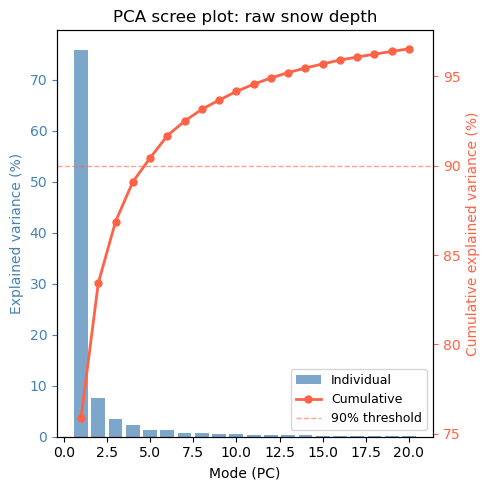

Modes needed to reach 90% explained variance: 5


In [ ]:
# Reshape to 2D matrix (time x pixels)
# Flatten spatial dimensions: reshape from (time, lat, lon) to (time, lat*lon)
n_time, n_lat, n_lon = sde_full.shape
sde_reshaped = sde_full.reshape(n_time, n_lat * n_lon)  # (time x pixels)

# Mask out invalid (NaN) pixels
# Create a mask of valid pixels (not NaN in any time step)
valid_pixel_mask = ~np.isnan(sde_reshaped).any(axis=0)  # find pixels valid at all times
n_valid_pixels = np.sum(valid_pixel_mask)

# Apply mask to keep only valid pixels
sde_pca = sde_reshaped[:, valid_pixel_mask]  # shape: (time x valid_pixels)

print(f"\nReshaping for PCA:")
print(f"  Original: {n_lat * n_lon} pixels × {n_time} time steps")
print(f"  Valid pixels (no NaN): {n_valid_pixels} pixels")
print(f"  Final PCA matrix shape (time x valid_pixels): {sde_pca.shape}")

# Standardize the data for PCA
pca_raw = PCA()
pca_raw.fit(sde_pca)  # fit PCA on the valid pixel data
explained_variance = pca_raw.explained_variance_ratio_  # variance explained
exp_var_raw_cum = np.cumsum(explained_variance)              # cumulative sum
print('Explained variance by mode (raw snow depth):')
for i in range(10):
    print(f'  PC{i+1}: {explained_variance[i]*100:.2f}%  '
          f'(cumulative: {exp_var_raw_cum[i]*100:.2f}%)')
# Modes needed to reach 90%
n_modes_90 = np.searchsorted(exp_var_raw_cum, 0.90) + 1      # modes needed to reach 90%
print(n_modes_90)

# Scree plot -- raw snow depth explained variance per mode

n_show = 20                                  # show first 20 modes
modes  = np.arange(1, n_show + 1)            # mode index array

fig, ax1 = plt.subplots(figsize=(5, 5))
ax2 = ax1.twinx()                            # second y-axis for cumulative variance

ax1.bar(modes, explained_variance[:n_show] * 100,color='steelblue', alpha=0.7, label='Individual')    # bar per mode
ax2.plot(modes, exp_var_raw_cum[:n_show] * 100,color='tomato', linewidth=2, 
         marker='o',markersize=5, label='Cumulative')                    # cumulative line
ax2.axhline(90, color='tomato', linestyle='--',linewidth=1, alpha=0.6, label='90% threshold')   # 90% reference line
ax1.set_xlabel('Mode (PC)')
ax1.set_ylabel('Explained variance (%)', color='steelblue')
ax2.set_ylabel('Cumulative explained variance (%)', color='tomato')
ax1.set_title('PCA scree plot: raw snow depth')
ax1.tick_params(axis='y', colors='steelblue')
ax2.tick_params(axis='y', colors='tomato')
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, fontsize=9, loc='lower right')
plt.tight_layout()
plt.show()

print(f'Modes needed to reach 90% explained variance: {n_modes_90}')


K-means on PC1 loadings: 3 clusters
Cluster sizes: [86751 17751  3027]


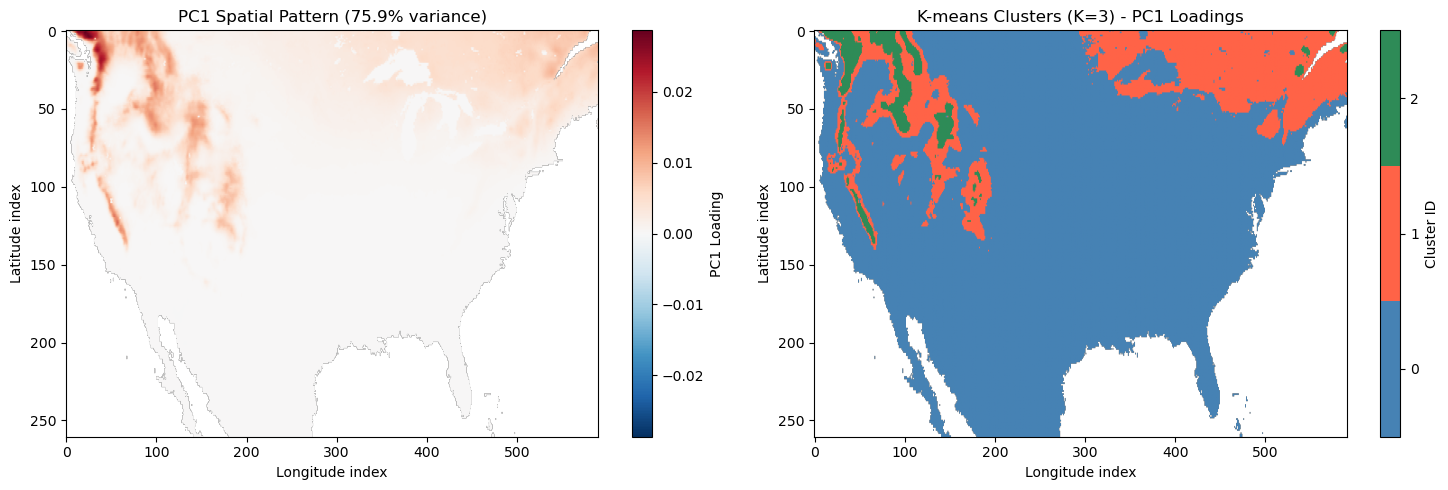

In [ ]:
# Extract PC1 loadings (spatial pattern) for clustering
pc1_loadings = pca_raw.components_[0, :]                               # shape: (n_valid_pixels,)
pc1_feature = pc1_loadings.reshape(-1, 1)                              # reshape to (n_valid_pixels, 1) for K-means

# Step 1: Elbow method to choose K
k_range = range(1, 11)
inertias = []



# Step 2: Choose K and fit K-means
K_selected = 3  # Based on elbow method (adjust if needed)
km_final = KMeans(n_clusters=K_selected, n_init=10, random_state=42)
km_final.fit(pc1_feature)
cluster_labels = km_final.labels_                                      # cluster assignment per pixel

print(f'K-means on PC1 loadings: {K_selected} clusters')
print(f'Cluster sizes: {np.bincount(cluster_labels)}')

# Step 3: Reshape PC1 loadings and cluster labels back to 2D grid
# Create full grid with NaN for invalid pixels
pc1_pattern_2d = np.full((n_lat, n_lon), np.nan)
cluster_grid = np.full((n_lat, n_lon), np.nan)

# Map valid pixels back to original positions
valid_indices = np.where(valid_pixel_mask)[0]
pc1_pattern_2d.flat[valid_indices] = pc1_loadings
cluster_grid.flat[valid_indices] = cluster_labels

# Step 4: Plot PC1 pattern and cluster map side by side
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Left panel: PC1 spatial pattern
ax = axes[0]
vmax_pc1 = np.nanmax(np.abs(pc1_pattern_2d))
im1 = ax.imshow(pc1_pattern_2d, cmap='RdBu_r', origin='upper', aspect='auto',
                 vmin=-vmax_pc1, vmax=vmax_pc1)
ax.set_title(f'PC1 Spatial Pattern ({explained_variance[0]*100:.1f}% variance)')
ax.set_xlabel('Longitude index')
ax.set_ylabel('Latitude index')
cbar1 = plt.colorbar(im1, ax=ax, label='PC1 Loading')

# Right panel: K-means cluster map
ax = axes[1]
cluster_colors = ['steelblue', 'tomato', 'seagreen', 'orange', 'purple'][:K_selected]
cmap_clusters = plt.matplotlib.colors.ListedColormap(cluster_colors)
im2 = ax.imshow(cluster_grid, cmap=cmap_clusters, origin='upper', aspect='auto',
                 vmin=-0.5, vmax=K_selected-0.5)
ax.set_title(f'K-means Clusters (K={K_selected}) - PC1 Loadings')
ax.set_xlabel('Longitude index')
ax.set_ylabel('Latitude index')
cbar2 = plt.colorbar(im2, ax=ax, label='Cluster ID', ticks=range(K_selected))

plt.tight_layout()
plt.show()


## Cateogry #4: Using Random Forest to determine which feature is most dominant 

#### Aligning time length and making sure the shape between all tree datasets is the same 

In [ ]:
#aligning datetime
ssrd['valid_time'] = ssrd['valid_time'].astype('datetime64[D]')
ssrd = ssrd.assign_coords(valid_time=ssrd['valid_time'].values.astype('datetime64[D]').astype('datetime64[ns]'))

#aligning time length
common_times = np.intersect1d(
    np.intersect1d(sde['valid_time'].values, t2m['valid_time'].values),
    ssrd['valid_time'].values)

sde  = sde.sel(valid_time=common_times)
t2m  = t2m.sel(valid_time=common_times)
ssrd = ssrd.sel(valid_time=common_times)

#regridding to sde spatial grid
t2m  = t2m.interp(latitude=sde['latitude'],  longitude=sde['longitude'],  method='nearest')
ssrd = ssrd.interp(latitude=sde['latitude'], longitude=sde['longitude'],  method='nearest')

#coarsening spatial grid
sde  = sde.coarsen(latitude=5, longitude=5, boundary='trim').mean()
t2m  = t2m.coarsen(latitude=5, longitude=5, boundary='trim').mean()
ssrd = ssrd.coarsen(latitude=5, longitude=5, boundary='trim').mean()

#dimensions across all 3 datasets are listed as valid_time (monthly), latitude, longitude

print(sde['valid_time'].values[:3])
print(t2m['valid_time'].values[:3])
print(ssrd['valid_time'].values[:3])
print('All shapes after alignment:', sde.shape, t2m.shape, ssrd.shape)

['1950-01-01T00:00:00.000000000' '1950-02-01T00:00:00.000000000'
 '1950-03-01T00:00:00.000000000']
['1950-01-01T00:00:00.000000000' '1950-02-01T00:00:00.000000000'
 '1950-03-01T00:00:00.000000000']
['1950-01-01T00:00:00.000000000' '1950-02-01T00:00:00.000000000'
 '1950-03-01T00:00:00.000000000']
All shapes after alignment: (912, 52, 118) (912, 52, 118) (912, 52, 118)


In [ ]:
#extracting latitude/longitude values
lats   = sde['latitude'].values
lons   = sde['longitude'].values
n_time = len(sde['valid_time'])
n_lat  = len(lats)
n_lon  = len(lons)
print(f'Dimensions: {n_time} months x {n_lat} lat x {n_lon} lon')

#converting datarray to numpy (n_time, n_lat, n_lon)
arr_sde  = sde.values    # snow depth  [m]
arr_t2m  = t2m.values    # temperature [K]
arr_ssrd = ssrd.values   # solar radiation [J/m²]

# Build month-of-year array broadcast to the same (n_time, n_lat, n_lon) shape
times_pd   = pd.DatetimeIndex(sde.valid_time.values)
months_2d = np.repeat(times_pd.month.to_numpy()[:, np.newaxis, np.newaxis], n_lat, axis=1)
arr_month  = np.repeat(months_2d, n_lon, axis=2).astype(float)

# Broadcast lat and lon to (n_time, n_lat, n_lon)
arr_lat = np.tile(lats[np.newaxis, :, np.newaxis], (n_time, 1, n_lon))
arr_lon = np.tile(lons[np.newaxis, np.newaxis, :], (n_time, n_lat, 1))

Dimensions: 912 months x 52 lat x 118 lon


In [ ]:
# Build sde lag (previous month's snow depth)
arr_sde_lag = np.full_like(arr_sde, np.nan)
arr_sde_lag[1:, :, :] = arr_sde[:-1, :, :]

# Stack all features into (n_time, n_lat, n_lon, 6) then flatten -- no loop needed
X_3d = np.stack([arr_lat, arr_lon, arr_month, arr_t2m, arr_ssrd, arr_sde_lag], axis=3)
y_3d = arr_sde

X_flat = X_3d.reshape(-1, 6)
y_flat = y_3d.reshape(-1)

# Drop rows with any NaN (ocean pixels, t=0 lag row, missing data)
valid   = np.isfinite(X_flat).all(axis=1) & np.isfinite(y_flat)
X       = X_flat[valid]
y       = y_flat[valid]

feature_cols = ['lat', 'lon', 'month', 't2m', 'ssrd', 'sde_lag']

#subsample to 1 million rows
np.random.seed(42)
sample_idx = np.random.choice(len(X), size=1_000_000, replace=False)
X_sample   = X[sample_idx]
y_sample   = y[sample_idx]

print(f'Sampled dataset: {X_sample.shape[0]:,} rows x {X_sample.shape[1]} columns')

Sampled dataset: 1,000,000 rows x 6 columns


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X_sample, y_sample, test_size=0.2, random_state=42)
print(f'Training: {X_train.shape[0]:,};  Test: {X_test.shape[0]:,}')


Training: 800,000;  Test: 200,000


### Category #4: Fitting a Random Forest regressor on our training dataset 

Random Forest -- RMSE: 0.040,  R2: 0.964


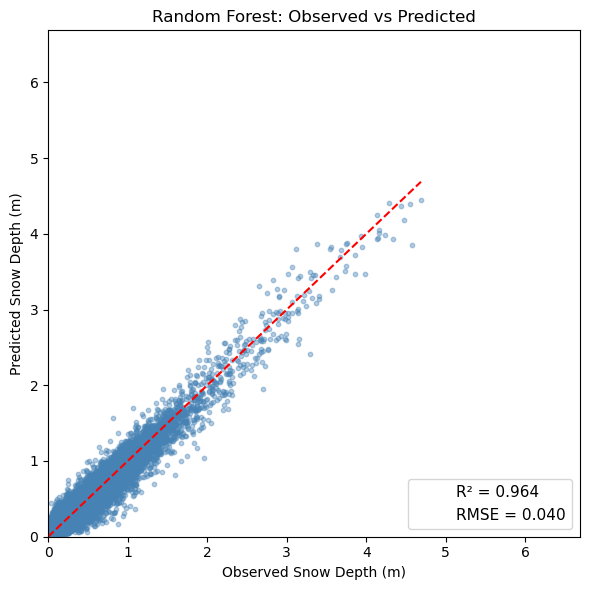

In [ ]:
rf = RandomForestRegressor(n_estimators=100, max_depth=15, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

#predicting on test set and evaluating model performance 
y_pred_rf = rf.predict(X_test)
r2_rf     = rf.score(X_test, y_test)
rmse_rf   = root_mean_squared_error(y_test, y_pred_rf)
print(f'Random Forest -- RMSE: {rmse_rf:.3f},  R2: {r2_rf:.3f}')

# Observed vs predicted plot -- Random Forest
all_min = min(y_test.min(), y_pred_rf.min())
all_max = max(y_test.max(), y_pred_rf.max())

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_test, y_pred_rf, color='steelblue', s=10, alpha=0.4)
ax.plot([all_min, all_max], [all_min, all_max], 'r--', linewidth=1.5)
ax.plot([], [], ' ', label=f'R\u00b2 = {r2_rf:.3f}')
ax.plot([], [], ' ', label=f'RMSE = {rmse_rf:.3f}')
ax.legend(loc='lower right', frameon=True, fontsize=11)
ax.set_xlim(all_min, all_max+2)
ax.set_ylim(all_min, all_max+2)
ax.set_xlabel('Observed Snow Depth (m)')
ax.set_ylabel('Predicted Snow Depth (m)')
ax.set_title('Random Forest: Observed vs Predicted')
plt.tight_layout()
plt.show()

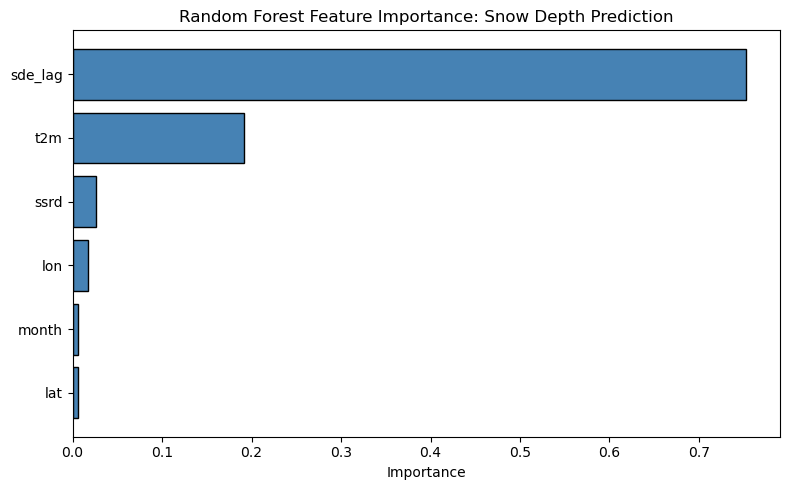

In [ ]:
#feature importance values and sorting
imp_rf    = rf.feature_importances_
order_rf  = np.argsort(imp_rf)   # ascending so most important is at top of barh

#plot
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(np.array(feature_cols)[order_rf], imp_rf[order_rf],
        color='steelblue', edgecolor='black')
ax.set_xlabel('Importance')
ax.set_title('Random Forest Feature Importance: Snow Depth Prediction')
plt.tight_layout()
plt.show()

## Computing SHAP values 

shap_values_rf shape: (1000, 6)


/var/folders/1d/y8qv9_pd2917xfw5j0tz4pg40000gn/T/ipykernel_39324/804839774.py:12: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values_rf, X_sample_rf, feature_names=feature_cols, show=True)


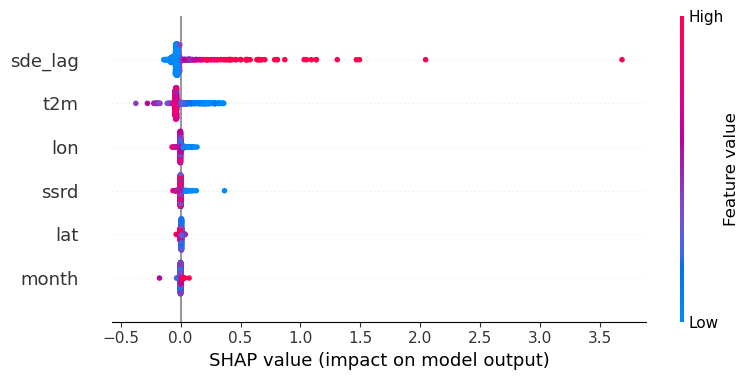

In [ ]:
## QUESTION 4 -- SHAP values, summary plot, interpret the top predictor
# Sample 1,000 pixel-months from the test set
sample_idx  = np.random.RandomState(42).choice(len(X_test), size=1000, replace=False)
X_sample_rf = X_test[sample_idx]

# Compute SHAP values for the Random Forest
explainer_rf   = shap.TreeExplainer(rf)
shap_values_rf = explainer_rf.shap_values(X_sample_rf)
print(f'shap_values_rf shape: {shap_values_rf.shape}')   # (1000, 5)

# SHAP summary plot (beeswarm)
shap.summary_plot(shap_values_rf, X_sample_rf, feature_names=feature_cols, show=True)

# Category #4: Random forest full completed model 

Resampling elevation...
Building sample table...
  Flat length: 656,640
  After cleaning: 176,575 rows
Fitting RF on 141,260 samples...
  R² = 0.6351  |  OOB R² = 0.6302  |  RMSE = 15.99 cm
Computing permutation importance...

Feature importance:
    feature     gini  perm_mean  perm_std
      t2m_c 0.495723   0.984764  0.017747
elevation_m 0.316223   0.427350  0.007504
 ssrd_wh_m2 0.188054   0.374109  0.008041
Saved: rf_importance_scatter.png
Saved: rf_spatial_maps.png


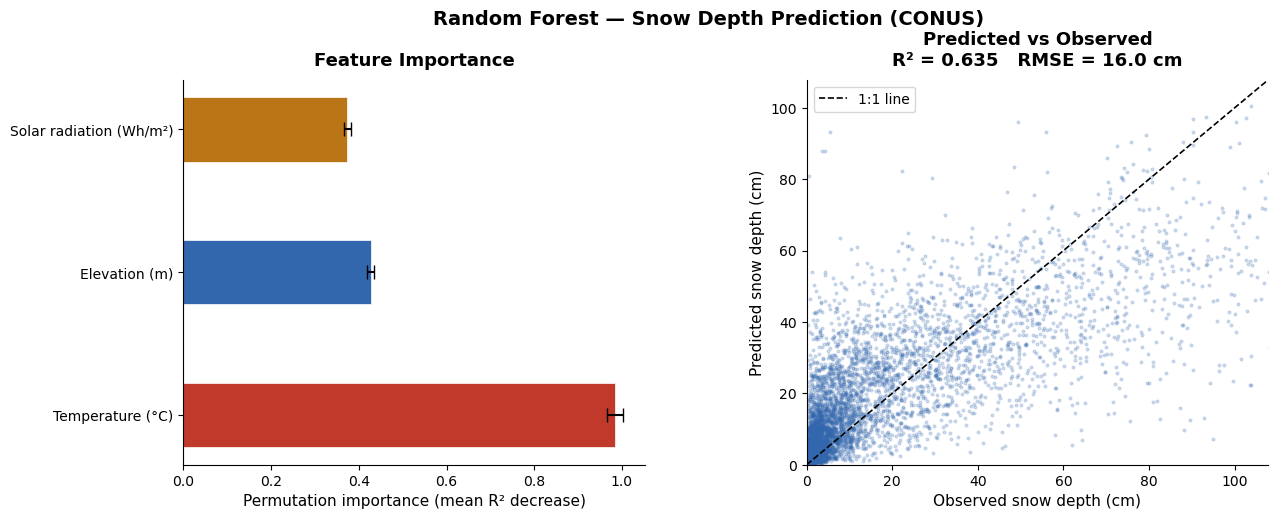

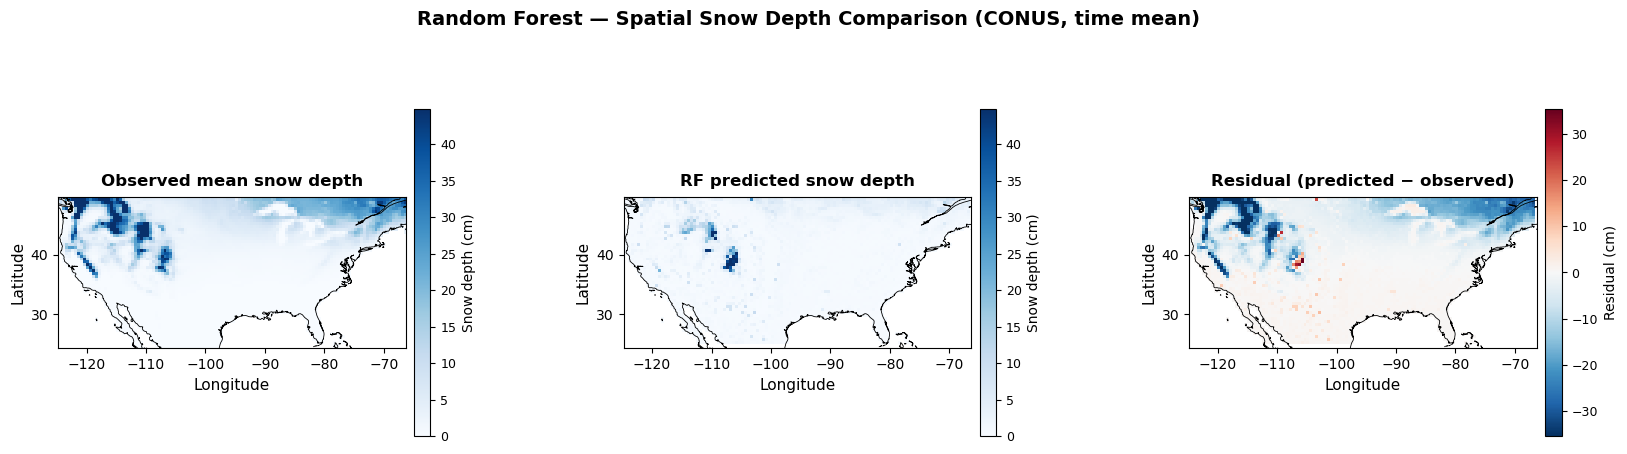

Done.


In [ ]:
"""
Random Forest: Snow Depth ~ Elevation + Temperature (t2m) + Solar Radiation (ssrd)
====================================================================================
Picks up directly from your existing preprocessing code.
All four datasets (sde, t2m, ssrd, elev) are assumed loaded and aligned
as described in your setup snippet.

Features:
  - elevation_m   : resampled to the coarsened ERA5 grid
  - t2m_c         : 2 m air temperature (°C)
  - ssrd_norm     : surface solar radiation downward (W/m² equivalent)
  - month         : calendar month (1–12)

Target:
  - sde (m)       : snow depth

Outputs:
  - rf_results.png        : importance + predicted vs actual + PDPs
  - rf_spatial_map.png    : observed vs predicted January snow depth map
  - rf_feature_importance.csv
"""

import os
import numpy as np
import pandas as pd
import xarray as xr
import rasterio
import rasterio.transform as rio_transform
from rasterio.warp import reproject, Resampling
from rasterio.crs import CRS
from rasterio.transform import array_bounds
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import geopandas as gpd
from cartopy.feature import NaturalEarthFeature
from shapely.geometry import shape
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.inspection import permutation_importance
import warnings
warnings.filterwarnings("ignore")
from affine import Affine

# ─────────────────────────────────────────────────────────────────
# 2.  RESAMPLE ELEVATION TO ERA5 GRID
# ─────────────────────────────────────────────────────────────────
print('Resampling elevation...')
 
lats_out     = sde['latitude'].values
lons_out     = sde['longitude'].values
lons_out_180 = lons_out - 360.0
n_lat, n_lon = len(lats_out), len(lons_out_180)
 
lon_res = float(lons_out_180[1] - lons_out_180[0])
lat_res = float(lats_out[0]     - lats_out[1])
 
# Affine is used to transform the elevation raster to the era5 and snowdepth grid. from_bounds didn't work so we are using Affine 
target_transform = Affine( 
    lon_res, 0.0, lons_out_180.min() - lon_res / 2,
    0.0, -lat_res, lats_out.max()    + lat_res / 2,
)
 
elev_resampled = np.full((n_lat, n_lon), np.nan, dtype=np.float32)
with rasterio.open(elev_file) as src:
    reproject(
        source        = rasterio.band(src, 1),
        destination   = elev_resampled,
        src_transform = src.transform,
        src_crs       = src.crs,
        dst_transform = target_transform,
        dst_crs       = CRS.from_epsg(4326),
        resampling    = Resampling.average,
        src_nodata    = nodata,
        dst_nodata    = np.nan,
    )
 
# ─────────────────────────────────────────────────────────────────
# 3.  BUILD SAMPLE TABLE  (spatially subsampled for speed)
# ─────────────────────────────────────────────────────────────────
print('Building sample table...')
 
sde_np  = sde.values                        # (time, lat, lon)
t2m_np  = t2m.values                        # (time, lat, lon)  Kelvin
ssrd_np = ssrd.values                       # (time, lat, lon)  J/m²
 
sde_nlat = sde_np.shape[1]
sde_nlon = sde_np.shape[2]
elev_matched = elev_resampled[:sde_nlat, :sde_nlon]
 
# ── subsample: use every 3rd pixel in space to cut rows ~9× ──
SPATIAL_STRIDE = 3
lat_idx = np.arange(0, sde_nlat, SPATIAL_STRIDE)
lon_idx = np.arange(0, sde_nlon, SPATIAL_STRIDE)
 
sde_sub  = sde_np [:, lat_idx[:, None], lon_idx]   # (time, lat_sub, lon_sub)
t2m_sub  = t2m_np [:, lat_idx[:, None], lon_idx]
ssrd_sub = ssrd_np[:, lat_idx[:, None], lon_idx]
elev_sub = elev_matched[lat_idx[:, None], lon_idx]  # (lat_sub, lon_sub)
 
n_sub_lat = len(lat_idx)
n_sub_lon = len(lon_idx)
n_pix     = n_sub_lat * n_sub_lon
 
# broadcast elevation across time, then flatten
elev_3d  = np.broadcast_to(elev_sub[np.newaxis], sde_sub.shape)
 
y_flat    = sde_sub.ravel()
t2m_flat  = t2m_sub.ravel()  - 273.15
ssrd_flat = ssrd_sub.ravel() / 3_600_000.0
elev_flat = np.array(elev_3d).ravel()
 
print(f'  Flat length: {len(y_flat):,}')
 
df = pd.DataFrame({
    'snow_depth_m' : y_flat,
    'elevation_m'  : elev_flat,
    't2m_c'        : t2m_flat,
    'ssrd_wh_m2'   : ssrd_flat,
})
df = df[(df['snow_depth_m'] >= 0) & (df['snow_depth_m'] < 10)].dropna()
print(f'  After cleaning: {len(df):,} rows')
 
# ─────────────────────────────────────────────────────────────────
# 4.  TRAIN / TEST  +  RANDOM FOREST
# ─────────────────────────────────────────────────────────────────
FEATURES = ['elevation_m', 't2m_c', 'ssrd_wh_m2']
LABELS   = {'elevation_m': 'Elevation (m)',
            't2m_c':       'Temperature (°C)',
            'ssrd_wh_m2':  'Solar radiation (Wh/m²)'}
COLORS   = {'elevation_m': '#3266ad', 't2m_c': '#c0392b', 'ssrd_wh_m2': '#BA7517'}
 
X = df[FEATURES].values
y = df['snow_depth_m'].values
 
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
 
print(f'Fitting RF on {len(X_train):,} samples...')
rf = RandomForestRegressor(
    n_estimators     = 200,
    max_depth        = 15,
    min_samples_leaf = 20,
    max_features     = 'sqrt',
    n_jobs           = -1,
    random_state     = 42,
    oob_score        = True,
)
rf.fit(X_train, y_train)
 
y_pred = rf.predict(X_test)
r2   = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
print(f'  R² = {r2:.4f}  |  OOB R² = {rf.oob_score_:.4f}  |  RMSE = {rmse*100:.2f} cm')
 
# Permutation importance (subsample test set for speed)
rng     = np.random.default_rng(42)
perm_n  = min(10_000, len(X_test))
perm_idx = rng.choice(len(X_test), perm_n, replace=False)
print('Computing permutation importance...')
perm = permutation_importance(rf, X_test[perm_idx], y_test[perm_idx],
                               n_repeats=10, random_state=42, n_jobs=-1)
 
imp_df = pd.DataFrame({
    'feature'  : FEATURES,
    'gini'     : rf.feature_importances_,
    'perm_mean': perm.importances_mean,
    'perm_std' : perm.importances_std,
}).sort_values('perm_mean', ascending=False)
 
print('\nFeature importance:')
print(imp_df.to_string(index=False))
imp_df.to_csv('rf_feature_importance.csv', index=False)
 
# ─────────────────────────────────────────────────────────────────
# 5.  SPATIAL PREDICTIONS: observed, predicted, residual
# ─────────────────────────────────────────────────────────────────
sde_mean_obs = np.nanmean(sde_np, axis=0)       # (lat, lon)
t2m_mean     = np.nanmean(t2m_np, axis=0)
ssrd_mean    = np.nanmean(ssrd_np, axis=0)
 
X_spatial = np.column_stack([
    elev_matched.ravel(),
    (t2m_mean.ravel()  - 273.15),
    (ssrd_mean.ravel() / 3_600_000.0),
])
nan_mask  = np.isnan(X_spatial).any(axis=1)
y_spatial = np.full(X_spatial.shape[0], np.nan)
y_spatial[~nan_mask] = rf.predict(X_spatial[~nan_mask])
 
pred_map = y_spatial.reshape(sde_nlat, sde_nlon)
residual = (pred_map - sde_mean_obs) * 100       # cm
 
lons_180 = lons_out[:sde_nlon] - 360.0
lons_2d, lats_2d = np.meshgrid(lons_180, lats_out[:sde_nlat])
 
coastline     = NaturalEarthFeature('physical', 'coastline', '50m')
coastline_gdf = gpd.GeoDataFrame(geometry=[shape(g) for g in coastline.geometries()])
 
def add_map_overlay(ax):
    coastline_gdf.plot(ax=ax, color='black', linewidth=0.6)
    ax.set_xlim(lons_180.min(), lons_180.max())
    ax.set_ylim(lats_out[:sde_nlat].min(), lats_out[:sde_nlat].max())
    ax.set_xlabel('Longitude', fontsize=11)
    ax.set_ylabel('Latitude',  fontsize=11)
    ax.tick_params(labelsize=10)
 
# ─────────────────────────────────────────────────────────────────
# 6.  FIGURE 1 — Feature importance + Predicted vs Actual
# ─────────────────────────────────────────────────────────────────
fig1, axes1 = plt.subplots(1, 2, figsize=(14, 5))
plt.subplots_adjust(wspace=0.35)
 
# ── Feature importance ──
ax_imp = axes1[0]
feats  = imp_df['feature'].tolist()
means  = imp_df['perm_mean'].tolist()
stds   = imp_df['perm_std'].tolist()
y_pos  = np.arange(len(feats))
ax_imp.barh(y_pos, means, xerr=stds,
            color=[COLORS[f] for f in feats],
            height=0.45, capsize=5, edgecolor='white', linewidth=0.5)
ax_imp.set_yticks(y_pos)
ax_imp.set_yticklabels([LABELS[f] for f in feats], fontsize=12)
ax_imp.set_xlabel('Permutation importance (mean R² decrease)', fontsize=11)
ax_imp.set_title('Feature Importance', fontsize=13, fontweight='bold', pad=10)
ax_imp.axvline(0, color='gray', lw=0.8, ls='--')
ax_imp.tick_params(labelsize=10)
ax_imp.spines['top'].set_visible(False)
ax_imp.spines['right'].set_visible(False)
 
# ── Predicted vs Actual ──
ax_sc  = axes1[1]
n_plot = min(8000, len(y_test))
idx_p  = rng.choice(len(y_test), n_plot, replace=False)
ax_sc.scatter(y_test[idx_p] * 100, y_pred[idx_p] * 100,
              alpha=0.2, s=4, color='#3266ad', rasterized=True)
lim = np.percentile(np.concatenate([y_test, y_pred]), 99) * 100 * 1.05
ax_sc.plot([0, lim], [0, lim], 'k--', lw=1.2, label='1:1 line')
ax_sc.set_xlabel('Observed snow depth (cm)',  fontsize=11)
ax_sc.set_ylabel('Predicted snow depth (cm)', fontsize=11)
ax_sc.set_title(f'Predicted vs Observed\nR² = {r2:.3f}   RMSE = {rmse*100:.1f} cm',
                fontsize=13, fontweight='bold', pad=10)
ax_sc.legend(fontsize=10)
ax_sc.tick_params(labelsize=10)
ax_sc.spines['top'].set_visible(False)
ax_sc.spines['right'].set_visible(False)
ax_sc.set_xlim(0, lim)
ax_sc.set_ylim(0, lim)
 
fig1.suptitle('Random Forest — Snow Depth Prediction (CONUS)',
              fontsize=14, fontweight='bold', y=1.02)
plt.savefig('rf_importance_scatter.png', dpi=150, bbox_inches='tight')
print('Saved: rf_importance_scatter.png')
 
# ─────────────────────────────────────────────────────────────────
# 7.  FIGURE 2 — Observed | Predicted | Residual maps
# ─────────────────────────────────────────────────────────────────
fig2, axes2 = plt.subplots(1, 3, figsize=(20, 5))
plt.subplots_adjust(wspace=0.35)
 
vmax_snow = np.nanpercentile(sde_mean_obs * 100, 98)
 
# ── Observed ──
ax_obs = axes2[0]
im0 = ax_obs.pcolormesh(lons_2d, lats_2d, sde_mean_obs * 100,
                         cmap='Blues', vmin=0, vmax=vmax_snow, shading='auto')
cb0 = plt.colorbar(im0, ax=ax_obs, label='Snow depth (cm)', shrink=0.85, pad=0.02)
cb0.ax.tick_params(labelsize=9)
add_map_overlay(ax_obs)
ax_obs.set_title('Observed mean snow depth', fontsize=12, fontweight='bold', pad=8)
 
# ── Predicted ──
ax_pred = axes2[1]
im1 = ax_pred.pcolormesh(lons_2d, lats_2d, pred_map * 100,
                          cmap='Blues', vmin=0, vmax=vmax_snow, shading='auto')
cb1 = plt.colorbar(im1, ax=ax_pred, label='Snow depth (cm)', shrink=0.85, pad=0.02)
cb1.ax.tick_params(labelsize=9)
add_map_overlay(ax_pred)
ax_pred.set_title('RF predicted snow depth', fontsize=12, fontweight='bold', pad=8)
 
# ── Residual ──
ax_res = axes2[2]
clim = np.nanpercentile(np.abs(residual), 98)
im2  = ax_res.pcolormesh(lons_2d, lats_2d, residual,
                          cmap='RdBu_r', vmin=-clim, vmax=clim, shading='auto')
cb2 = plt.colorbar(im2, ax=ax_res, label='Residual (cm)', shrink=0.85, pad=0.02)
cb2.ax.tick_params(labelsize=9)
add_map_overlay(ax_res)
ax_res.set_title('Residual (predicted − observed)', fontsize=12, fontweight='bold', pad=8)
 
fig2.suptitle('Random Forest — Spatial Snow Depth Comparison (CONUS, time mean)',
              fontsize=14, fontweight='bold', y=1.02)
plt.savefig('rf_spatial_maps.png', dpi=150, bbox_inches='tight')
print('Saved: rf_spatial_maps.png')
 
plt.show()
print('Done.')
 

# Category 2: Biplot with elevation, ssrd, temperature, and snowdepth

### Setting up the PCA variables for plotting 

In [ ]:
VAR_COLS   = ['elevation_m', 't2m_c', 'ssrd_wh_m2', 'snow_depth_m']
VAR_LABELS = ['Elevation (m)', 'Temperature (°C)', 'Solar radiation (Wh/m²)', 'Snow depth (m)']
VAR_COLORS = ['#3266ad', '#c0392b', '#BA7517', '#1D9E75']

rng    = np.random.default_rng(42)
n_plot = min(5000, len(df))
idx    = rng.choice(len(df), n_plot, replace=False)
X_plot = df[VAR_COLS].iloc[idx].values

scaler   = StandardScaler()
X_scaled = scaler.fit_transform(X_plot)

pca      = PCA(n_components=2)
scores   = pca.fit_transform(X_scaled)
loadings = pca.components_.T
var_exp  = pca.explained_variance_ratio_ * 100

print(f'PC1: {var_exp[0]:.1f}%  |  PC2: {var_exp[1]:.1f}%')

PC1: 45.1%  |  PC2: 33.3%


### Plotting Biplot 

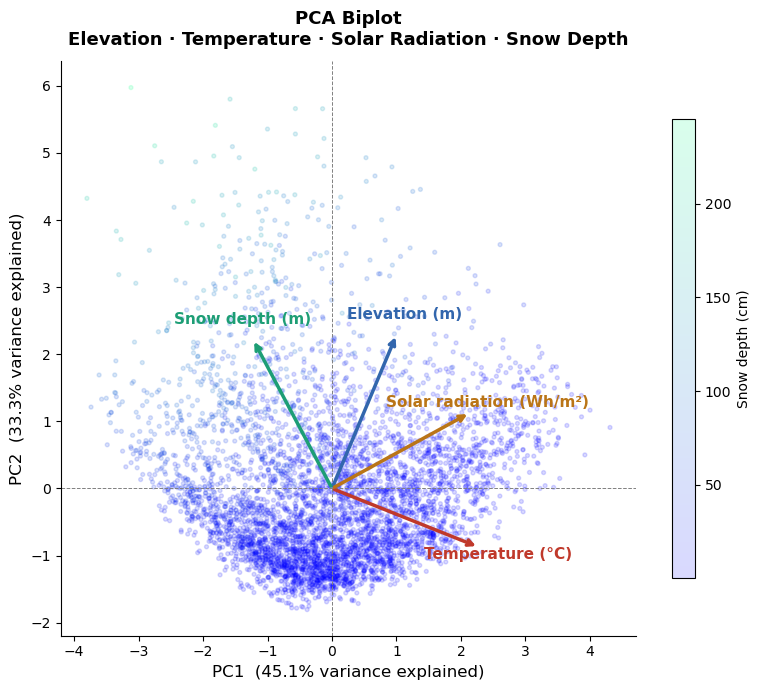

In [ ]:
fig, ax = plt.subplots(figsize=(8, 7))

snow_vals = df['snow_depth_m'].iloc[idx].values * 100
sc = ax.scatter(scores[:, 0], scores[:, 1],
                c=snow_vals, cmap='winter', s=8, alpha=0.15, rasterized=True)
plt.colorbar(sc, ax=ax, label='Snow depth (cm)', shrink=0.8)

scale = 3.5
for i, (label, col) in enumerate(zip(VAR_LABELS, VAR_COLORS)):
    lx, ly = loadings[i, 0] * scale, loadings[i, 1] * scale
    ax.annotate('', xy=(lx, ly), xytext=(0, 0),
                arrowprops=dict(arrowstyle='->', color=col, lw=2.5))
    ax.text(lx * 1.13, ly * 1.13, label,
            color=col, fontsize=11, fontweight='bold', ha='center', va='center')

ax.axhline(0, color='gray', lw=0.7, ls='--')
ax.axvline(0, color='gray', lw=0.7, ls='--')
ax.set_xlabel(f'PC1  ({var_exp[0]:.1f}% variance explained)', fontsize=12)
ax.set_ylabel(f'PC2  ({var_exp[1]:.1f}% variance explained)', fontsize=12)
ax.set_title('PCA Biplot\nElevation · Temperature · Solar Radiation · Snow Depth',
             fontsize=13, fontweight='bold', pad=12)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('biplot.png', dpi=150, bbox_inches='tight')
plt.show()